In [1]:
!pip install -q transformers datasets accelerate evaluate

from google.colab import drive
drive.mount('/content/drive')

import os, time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.8 MB/s eta 0:00:00
Mounted at /content/drive
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB


In [2]:
DATA_DIR   = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

OUTPUT_DIR = f"{DATA_DIR}/roberta_therapistqa_seed42_v3"
FINAL_DIR  = f"{DATA_DIR}/roberta_therapistqa_final_v3"

df_train = pd.read_csv(f"{DATA_DIR}/therapistqa_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/therapistqa_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")

classes  = sorted(df_train["dominant_distortion"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"Classes ({len(classes)}):")
for idx, name in id2label.items():
    print(f"  {idx}: {name}")

Train: 1768, Val: 379, Test: 379
Classes (11):
  0: All-or-nothing thinking
  1: Emotional Reasoning
  2: Fortune-telling
  3: Labeling
  4: Magnification
  5: Mental filter
  6: Mind Reading
  7: No Distortion
  8: Overgeneralization
  9: Personalization
  10: Should statements


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["patient_question", "dominant_distortion"]]
            .rename(columns={"patient_question": "text"})
            .assign(label=lambda d: d["dominant_distortion"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=512)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, remove_columns=["text"])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1768 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

In [4]:
y_train = df_train["dominant_distortion"].map(label2id).values
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label2id)),
    y=y_train,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda")

print("Class weights:")
for idx, w in enumerate(class_weights):
    print(f"  {id2label[idx]:<25} {w:.3f}")

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    id2label=id2label,
    label2id=label2id,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=10,
    max_grad_norm=1.0,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=4)],
)

Class weights:
  All-or-nothing thinking   2.329
  Emotional Reasoning       1.710
  Fortune-telling           1.591
  Labeling                  1.398
  Magnification             1.182
  Mental filter             1.869
  Mind Reading              0.962
  No Distortion             0.247
  Overgeneralization        0.962
  Personalization           1.516
  Should statements         2.143


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [5]:
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.402655,2.393084,0.076517,0.036267,0.025061
2,2.372418,2.319184,0.327177,0.263422,0.088860
3,2.235195,2.218970,0.324538,0.321527,0.182787
4,2.011907,2.240041,0.366755,0.337791,0.200851
5,1.697673,2.287529,0.282322,0.293697,0.172216
6,1.379991,2.350394,0.308707,0.319029,0.209888
7,1.088081,2.488467,0.343008,0.343317,0.216514
8,0.861866,2.562589,0.324538,0.340052,0.231303
9,0.705482,2.638813,0.321900,0.340295,0.220401
10,0.605867,2.689977,0.319261,0.337265,0.224214


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 30.8 minutes


In [6]:
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Saved final model and tokenizer to {FINAL_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model and tokenizer to /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_final_v3


=== Test set metrics ===
  test_loss: 2.2457
  test_accuracy: 0.3668
  test_f1_weighted: 0.3721
  test_f1_macro: 0.2681
  test_runtime: 11.5027
  test_samples_per_second: 32.9490
  test_steps_per_second: 1.0430

=== Per-category report ===
                         precision    recall  f1-score   support

All-or-nothing thinking      0.167     0.133     0.148        15
    Emotional Reasoning      0.143     0.100     0.118        20
        Fortune-telling      0.250     0.238     0.244        21
               Labeling      0.160     0.160     0.160        25
          Magnification      0.240     0.414     0.304        29
          Mental filter      0.167     0.222     0.190        18
           Mind Reading      0.304     0.472     0.370        36
          No Distortion      0.702     0.521     0.598       140
     Overgeneralization      0.158     0.083     0.109        36
        Personalization      0.333     0.478     0.393        23
      Should statements      0.273     0.375

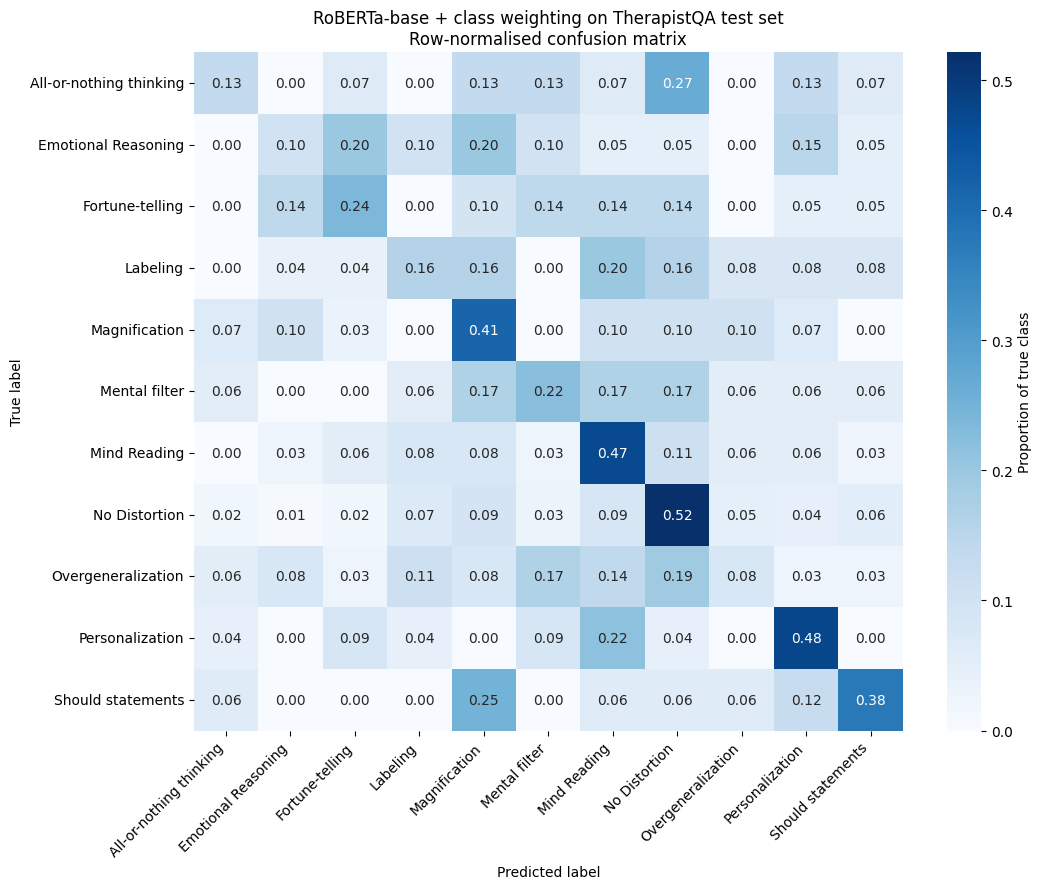

Saved confusion matrix to /content/drive/MyDrive/thesis_stage2/confusion_matrix_therapistqa_v3.png


In [7]:
test_predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

print("\n=== Per-category report ===")
print(classification_report(
    y_true, y_pred,
    target_names=[id2label[i] for i in range(len(id2label))],
    digits=3,
))

# Predictions CSV with per-class probabilities
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
    "text":       df_test["patient_question"].values,
})

probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{id2label[idx]}"] = probs[:, idx]

predictions_csv = f"{DATA_DIR}/roberta_therapistqa_test_predictions_v3.csv"
predictions_df.to_csv(predictions_csv, index=False)
print(f"\nSaved predictions to {predictions_csv}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
labels = [id2label[i] for i in range(len(id2label))]
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=labels, yticklabels=labels,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("RoBERTa-base + class weighting on TherapistQA test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = f"{DATA_DIR}/confusion_matrix_therapistqa_v3.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrix to {cm_path}")